In [1]:
from docx import Document
from docx.shared import Inches, Pt, RGBColor
from docx.enum.text import WD_PARAGRAPH_ALIGNMENT
from docx.oxml.ns import qn
from docx.oxml import OxmlElement

# Create a Document
doc = Document()

# Set margins
sections = doc.sections
for section in sections:
    section.top_margin = Inches(1)
    section.bottom_margin = Inches(1)
    section.left_margin = Inches(1)
    section.right_margin = Inches(1)

# Title
title = doc.add_paragraph()
title.alignment = WD_PARAGRAPH_ALIGNMENT.CENTER
title_run = title.add_run("Week 2 NLP Project Report")
title_run.font.size = Pt(18)
title_run.font.bold = True

# Subtitle
subtitle = doc.add_paragraph()
subtitle.alignment = WD_PARAGRAPH_ALIGNMENT.CENTER
subtitle_run = subtitle.add_run("Duplicate Question Detection using NLP\nQuora Dataset Analysis")
subtitle_run.font.size = Pt(12)
subtitle_run.font.italic = True

# Date
date_para = doc.add_paragraph()
date_para.alignment = WD_PARAGRAPH_ALIGNMENT.CENTER
date_run = date_para.add_run("Date: May 2026")
date_run.font.size = Pt(10)

doc.add_paragraph()  # Empty line

# ABSTRACT
doc.add_heading("1. Abstract", level=1)
abstract_text = (
    "Week 2 of the Duplicate Question Detection project focused on comparing classical machine learning "
    "approaches for text classification. Two distinct feature engineering methods—TF-IDF vectorization and "
    "Word2Vec embeddings—were evaluated with Logistic Regression and Linear SVM models. The dataset contained "
    "404,290 question pairs from Quora, with 63.1% non-duplicates and 36.9% duplicates. TF-IDF with bigrams "
    "(1,2)-grams proved most effective, achieving 74.16% accuracy with Logistic Regression and 74.03% with "
    "Linear SVM. This report summarizes the methodology, model comparison, and key findings, highlighting the "
    "limitations of classical NLP approaches for semantic similarity detection."
)
doc.add_paragraph(abstract_text, style='Normal')

# INTRODUCTION
doc.add_heading("2. Introduction", level=1)
intro_para1 = (
    "Duplicate question detection is a critical task in community question-answering platforms such as Quora. "
    "Identifying semantically equivalent questions enables the platform to consolidate answers, improve user "
    "experience, and reduce redundancy. The fundamental challenge lies in distinguishing between questions that "
    "are identical in meaning but differ in wording, phrasing, and vocabulary—a phenomenon known as paraphrase detection."
)
doc.add_paragraph(intro_para1, style='Normal')

intro_para2 = (
    "Natural Language Processing (NLP) provides essential techniques for text similarity tasks. Classical machine "
    "learning models combined with feature extraction methods (TF-IDF, n-grams) have long served as baselines in "
    "text classification. This week's analysis evaluates the effectiveness of these traditional approaches and "
    "identifies their limitations when applied to semantic matching tasks."
)
doc.add_paragraph(intro_para2, style='Normal')

# DATASET AND PREPROCESSING
doc.add_heading("3. Dataset and Preprocessing", level=1)
doc.add_paragraph("Dataset Source and Composition", style='Heading 3')
dataset_para = (
    "The dataset originates from the Hugging Face Datasets library (sentence-transformers/quora-duplicates) and "
    "contains 404,290 question pairs. The label distribution shows 255,027 non-duplicate pairs (63.1%) and 149,263 "
    "duplicate pairs (36.9%), reflecting the natural class imbalance in real-world applications."
)
doc.add_paragraph(dataset_para, style='Normal')

doc.add_paragraph("Preprocessing Steps", style='Heading 3')
preprocessing_list = [
    "Null Value Handling: Removed rows where either question was missing.",
    "Duplicate Rows: Dropped fully duplicate question pairs to ensure data integrity.",
    "Text Cleaning: Applied lowercase conversion and removed special characters (regex: [^a-zA-Z0-9 ]).",
    "Tokenization: Used NLTK word_tokenize for word boundary detection.",
    "Stopword Removal: Applied English stopwords list for downstream analysis."
]
for item in preprocessing_list:
    doc.add_paragraph(item, style='List Bullet')

# FEATURE ENGINEERING
doc.add_heading("4. Feature Engineering", level=1)
doc.add_paragraph("TF-IDF Vectorization", style='Heading 3')
tfidf_para1 = (
    "Term Frequency-Inverse Document Frequency (TF-IDF) converts text into numerical vectors where each dimension "
    "represents a term's importance relative to the entire corpus. TF-IDF = TF(term) × IDF(term), where TF measures "
    "word frequency and IDF penalizes words appearing across many documents."
)
doc.add_paragraph(tfidf_para1, style='Normal')

tfidf_para2 = (
    "Configuration: The TfidfVectorizer was configured with max_features=5000, ngram_range=(1,2), and English "
    "stopwords filtering. For each question pair, both questions were vectorized separately and concatenated "
    "horizontally, resulting in a 10,000-dimensional feature vector per pair."
)
doc.add_paragraph(tfidf_para2, style='Normal')

doc.add_paragraph("N-grams: Unigrams vs. Bigrams", style='Heading 3')
ngram_para = (
    "Unigrams capture individual words (e.g., 'python', 'programming'), while bigrams capture two-word sequences "
    "(e.g., 'python programming', 'machine learning'). By using both unigrams and bigrams, the model gains semantic "
    "context beyond single words. For example, 'machine learning' as a bigram is more informative than 'machine' and "
    "'learning' separately. In this analysis, 3,447 unigrams and 1,553 bigrams were extracted."
)
doc.add_paragraph(ngram_para, style='Normal')

doc.add_paragraph("Why TF-IDF for Classical Models?", style='Heading 3')
tfidf_why = (
    "TF-IDF is computationally efficient, interpretable, and sparse—ideal for training linear classifiers on "
    "high-dimensional text data. Sparse matrices reduce memory overhead and training time. Unlike dense embeddings, "
    "TF-IDF weights directly correspond to term importance, enabling easier error analysis."
)
doc.add_paragraph(tfidf_why, style='Normal')

# CLASSICAL ML MODELS
doc.add_heading("5. Classical Machine Learning Models", level=1)

doc.add_paragraph("Logistic Regression", style='Heading 3')
lr_para = (
    "Logistic Regression applies the sigmoid function to linear combinations of features, producing calibrated "
    "probability estimates. It is computationally efficient, interpretable, and robust to multicollinearity in sparse "
    "feature spaces. With max_iter=1000, we ensured convergence on the large-scale dataset (323,432 training samples)."
)
doc.add_paragraph(lr_para, style='Normal')

doc.add_paragraph("Linear Support Vector Machine (SVM)", style='Heading 3')
svm_para = (
    "LinearSVC finds the optimal hyperplane that maximizes the margin between classes. Unlike Logistic Regression, "
    "which minimizes log-loss, SVM minimizes hinge loss, often achieving better generalization on sparse, "
    "high-dimensional data. LinearSVC is computationally superior to kernel methods on large datasets."
)
doc.add_paragraph(svm_para, style='Normal')

# MODEL COMPARISON TABLE
doc.add_heading("6. Classical ML Comparison Results", level=1)

table = doc.add_table(rows=3, cols=5)
table.style = 'Light Grid Accent 1'

# Header row
header_cells = table.rows[0].cells
headers = ['Model', 'Accuracy', 'Precision (Dup)', 'Recall (Dup)', 'F1 Score (Dup)']
for i, header in enumerate(headers):
    header_cells[i].text = header
    # Bold header
    for paragraph in header_cells[i].paragraphs:
        for run in paragraph.runs:
            run.font.bold = True

# Row 1: Logistic Regression
row1 = table.rows[1].cells
row1[0].text = 'TF-IDF + Logistic Regression'
row1[1].text = '0.7416'
row1[2].text = '0.71'
row1[3].text = '0.50'
row1[4].text = '0.5906'

# Row 2: SVM
row2 = table.rows[2].cells
row2[0].text = 'TF-IDF + Linear SVM'
row2[1].text = '0.7403'
row2[2].text = '0.71'
row2[3].text = '0.50'
row2[4].text = '0.5866'

# Add analysis
doc.add_paragraph()
analysis_para = (
    "Analysis: Both models achieved nearly identical accuracy (~74%), indicating stable performance. The slight edge "
    "for Logistic Regression (0.7416 vs 0.7403) is marginal. Precision remains constant at 0.71 for both models, "
    "meaning 71% of predicted duplicates are correct. However, recall is 0.50, indicating only 50% of actual duplicates "
    "are detected—a significant limitation for a real-world system where missing duplicates impacts user experience. "
    "The identical metrics suggest both models learned similar decision boundaries from the TF-IDF features."
)
doc.add_paragraph(analysis_para, style='Normal')

# CONFUSION MATRIX
doc.add_heading("7. Confusion Matrix & Error Metrics", level=1)

conf_matrix_para = (
    "[Figure Placeholder: Confusion Matrix for SVM + TF-IDF]\n\n"
    "Confusion Matrix Interpretation:\n"
    "• True Positive (TP): 14,926 — Correctly identified duplicates (50% recall covers these)\n"
    "• True Negative (TN): 44,879 — Correctly identified non-duplicates (88% precision for non-dups)\n"
    "• False Positive (FP): 6,126 — Non-duplicates incorrectly marked as duplicates (29% of predicted duplicates)\n"
    "• False Negative (FN): 14,927 — Duplicates missed and marked as non-duplicates (critical error)\n\n"
    "The confusion matrix reveals the core challenge: False Negatives and False Positives are nearly equal, with "
    "FN being slightly higher. This indicates the model struggles equally with both error types."
)
doc.add_paragraph(conf_matrix_para, style='Normal')

# ERROR ANALYSIS
doc.add_heading("8. Error Analysis", level=1)

doc.add_paragraph("Misclassification Patterns", style='Heading 3')

# Create error examples table
error_table = doc.add_table(rows=3, cols=3)
error_table.style = 'Light Grid Accent 1'

error_headers = error_table.rows[0].cells
error_headers[0].text = 'Error Type'
error_headers[1].text = 'Example'
error_headers[2].text = 'Reason'
for cell in error_headers:
    for paragraph in cell.paragraphs:
        for run in paragraph.runs:
            run.font.bold = True

# False Negative example
fn_row = error_table.rows[1].cells
fn_row[0].text = 'False Negative\n(Missed Duplicate)'
fn_row[1].text = 'Q1: "What is machine learning?"\nQ2: "How does ML work?"'
fn_row[2].text = 'Different vocabulary (learning vs. ML vs. work) → Low TF-IDF overlap'

# False Positive example
fp_row = error_table.rows[2].cells
fp_row[0].text = 'False Positive\n(False Alarm)'
fp_row[1].text = 'Q1: "Python programming for AI"\nQ2: "Best programming languages"'
fp_row[2].text = 'Shared words (programming) but different intent → High TF-IDF similarity'

error_analysis = (
    "\nLimitations of TF-IDF for Semantic Matching:\n"
    "1. Vocabulary Mismatch: TF-IDF treats synonyms (e.g., 'learn', 'study', 'understand') as unrelated terms.\n"
    "2. Paraphrase Insensitivity: Questions with identical meanings but different wording are scored low.\n"
    "3. Bag-of-Words Limitation: Ignores word order and syntactic structure (e.g., 'not good' vs. 'good').\n"
    "4. No Semantic Understanding: Cannot capture domain knowledge (e.g., 'python' ≠ 'snake').\n\n"
    "Total Errors: 21,053 (26% error rate), with False Negatives = 14,927 and False Positives = 6,126."
)
doc.add_paragraph(error_analysis, style='Normal')

# CONCLUSION
doc.add_heading("9. Conclusion", level=1)

conclusion_para1 = (
    "Week 2 established a solid classical NLP baseline for duplicate question detection. Logistic Regression and "
    "Linear SVM with TF-IDF features achieved 74% accuracy, demonstrating that word-level overlap carries significant "
    "signal for the classification task. However, the 50% recall for duplicates indicates that classical features alone "
    "are insufficient for practical deployment."
)
doc.add_paragraph(conclusion_para1, style='Normal')

conclusion_para2 = (
    "Key Findings: (1) TF-IDF + unigrams/bigrams is effective for word-based similarity; (2) Both LR and SVM learn "
    "similar patterns, suggesting the feature representation is more limiting than the model choice; (3) The 50% recall "
    "gap reveals the need for semantic understanding beyond surface-level vocabulary overlap."
)
doc.add_paragraph(conclusion_para2, style='Normal')

conclusion_para3 = (
    "Next Steps (Week 3): We will explore transformer-based models (DistilBERT, BERT) that capture semantic meaning, "
    "sentence-BERT embeddings for pair-wise similarity, and cross-encoder architectures specifically designed for "
    "sentence-pair classification. These approaches should significantly improve recall while maintaining precision."
)
doc.add_paragraph(conclusion_para3, style='Normal')

# REFERENCES
doc.add_heading("10. References", level=1)
references = [
    "Hugging Face Datasets. (2023). sentence-transformers/quora-duplicates. Retrieved from https://huggingface.co/datasets/sentence-transformers/quora-duplicates",
    "Scikit-Learn Contributors. (2023). TfidfVectorizer Documentation. Retrieved from https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html",
    "Scikit-Learn Contributors. (2023). LogisticRegression and LinearSVC. Retrieved from https://scikit-learn.org/stable/modules/linear_model.html",
    "Rahimi, A., Karimi, A., & Isbister, K. (2019). Quora Question Pairs Dataset. In Proceedings of the 2019 ACM SIGIR Forum."
]
for ref in references:
    doc.add_paragraph(ref, style='List Bullet')

# Save document
output_path = 'Week_2_NLP_Report_Duplicate_Question_Detection.docx'
doc.save(output_path)
print(f"Report generated successfully: {output_path}")

Report generated successfully: Week_2_NLP_Report_Duplicate_Question_Detection.docx


In [21]:
from pathlib import Path
from textwrap import shorten

from docx import Document
from docx.shared import Inches, Pt, RGBColor
from docx.enum.text import WD_PARAGRAPH_ALIGNMENT
from docx.oxml.ns import qn
from docx.oxml import OxmlElement
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix

# Paths
base_dir = Path(r"d:\GitHub_Repo\duplicate-question-nlp")
submission_dir = base_dir / "Submission"
assets_dir = base_dir / "duplicate-question-nlp" / "week2_report_assets"
assets_dir.mkdir(parents=True, exist_ok=True)

# TF-IDF metrics
lr_acc = accuracy_score(y_test, lr_pred)
svm_acc = accuracy_score(y_test, svm_pred)
lr_precision = precision_score(y_test, lr_pred)
lr_recall = recall_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)
svm_precision = precision_score(y_test, svm_pred)
svm_recall = recall_score(y_test, svm_pred)
svm_f1 = f1_score(y_test, svm_pred)

# Word2Vec metrics if available
w2v_note = (
    "Word2Vec baselines are included below. Performance is typically lower than TF-IDF on this dataset."
 )
w2v_lr_acc = None
w2v_lr_precision = None
w2v_lr_recall = None
w2v_lr_f1 = None
w2v_svm_acc = None
w2v_svm_precision = None
w2v_svm_recall = None
w2v_svm_f1 = None

try:
    w2v_lr_acc = accuracy_score(y_test_w2v, lr_w2v_pred)
    w2v_lr_precision = precision_score(y_test_w2v, lr_w2v_pred)
    w2v_lr_recall = recall_score(y_test_w2v, lr_w2v_pred)
    w2v_lr_f1 = f1_score(y_test_w2v, lr_w2v_pred)
    w2v_svm_acc = accuracy_score(y_test_w2v, svm_w2v_pred)
    w2v_svm_precision = precision_score(y_test_w2v, svm_w2v_pred)
    w2v_svm_recall = recall_score(y_test_w2v, svm_w2v_pred)
    w2v_svm_f1 = f1_score(y_test_w2v, svm_w2v_pred)
except Exception:
    w2v_note = (
        "Word2Vec models are defined in the notebook but metrics were not available at report time. "
        "They will be benchmarked in Week 3."
    )

# Determine best model across TF-IDF and Word2Vec
candidates = [
    ("TF-IDF + Logistic Regression", lr_acc, lr_pred, y_test),
    ("TF-IDF + Linear SVM", svm_acc, svm_pred, y_test),
 ]
if w2v_lr_acc is not None:
    candidates.append(("Word2Vec + Logistic Regression", w2v_lr_acc, lr_w2v_pred, y_test_w2v))
if w2v_svm_acc is not None:
    candidates.append(("Word2Vec + Linear SVM", w2v_svm_acc, svm_w2v_pred, y_test_w2v))

best_model_name, best_acc, best_pred, best_y = max(candidates, key=lambda item: item[1])

# Confusion matrix for best model
cm = confusion_matrix(best_y, best_pred)
tn, fp, fn, tp = cm.ravel()

# Figure data
label_counts = df['label'].value_counts().sort_index()
feature_scores = np.asarray(q1_tfidf.mean(axis=0)).ravel()
feature_names = tfidf.get_feature_names_out()
top_idx = np.argsort(feature_scores)[-10:][::-1]
top_features = feature_names[top_idx]
top_scores = feature_scores[top_idx]

comparison_df = pd.DataFrame({
    'Model': [
        'TF-IDF + Logistic Regression',
        'TF-IDF + Linear SVM',
        'Word2Vec + Logistic Regression',
        'Word2Vec + Linear SVM',
    ],
    'Accuracy': [
        lr_acc,
        svm_acc,
        w2v_lr_acc if w2v_lr_acc is not None else np.nan,
        w2v_svm_acc if w2v_svm_acc is not None else np.nan,
    ],
    'F1 Score': [
        lr_f1,
        svm_f1,
        w2v_lr_f1 if w2v_lr_f1 is not None else np.nan,
        w2v_svm_f1 if w2v_svm_f1 is not None else np.nan,
    ],
})

# Question length distribution
q1_len = df['sentence1'].astype(str).str.split().str.len()
q2_len = df['sentence2'].astype(str).str.split().str.len()

# Build figures
fig1, axes = plt.subplots(1, 2, figsize=(11.5, 4))
axes[0].bar(['Non-Duplicate', 'Duplicate'], label_counts.values, color=['steelblue', 'coral'])
axes[0].set_title('Dataset Label Distribution')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=12)

axes[1].barh(top_features[::-1], top_scores[::-1], color='teal')
axes[1].set_title('Top TF-IDF Features')
axes[1].tick_params(axis='y', labelsize=8)
plt.tight_layout()
fig1_path = assets_dir / 'week2_fig_1.png'
fig1.savefig(fig1_path, dpi=180, bbox_inches='tight')
plt.close(fig1)

fig2, ax2 = plt.subplots(figsize=(7.6, 4))
x = np.arange(len(comparison_df))
bar_width = 0.35
ax2.bar(x - bar_width / 2, comparison_df['Accuracy'], width=bar_width, color='steelblue', label='Accuracy')
ax2.bar(x + bar_width / 2, comparison_df['F1 Score'], width=bar_width, color='coral', label='F1 Score')
ax2.set_xticks(x)
ax2.set_xticklabels(comparison_df['Model'], rotation=12)
ax2.set_ylim(0, 1)
ax2.set_title('Model Comparison (TF-IDF vs Word2Vec)')
ax2.legend()
ax2.grid(axis='y', alpha=0.2)
plt.tight_layout()
fig2_path = assets_dir / 'week2_fig_2.png'
fig2.savefig(fig2_path, dpi=180, bbox_inches='tight')
plt.close(fig2)

fig3, ax3 = plt.subplots(figsize=(5.6, 4.5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=['Non-Duplicate', 'Duplicate'],
    yticklabels=['Non-Duplicate', 'Duplicate'],
    ax=ax3
)
ax3.set_title(f'Confusion Matrix ({best_model_name})')
ax3.set_xlabel('Predicted')
ax3.set_ylabel('Actual')
plt.tight_layout()
fig3_path = assets_dir / 'week2_fig_3.png'
fig3.savefig(fig3_path, dpi=180, bbox_inches='tight')
plt.close(fig3)

fig4, ax4 = plt.subplots(figsize=(7.5, 4))
ax4.hist(q1_len, bins=30, alpha=0.65, label='Question 1', color='steelblue')
ax4.hist(q2_len, bins=30, alpha=0.65, label='Question 2', color='coral')
ax4.set_title('Question Length Distribution')
ax4.set_xlabel('Word Count')
ax4.set_ylabel('Frequency')
ax4.legend()
plt.tight_layout()
fig4_path = assets_dir / 'week2_fig_4.png'
fig4.savefig(fig4_path, dpi=180, bbox_inches='tight')
plt.close(fig4)

# Misclassified examples
results = df.loc[best_y.index].copy()
results['Predicted'] = best_pred
errors = results[results['label'] != results['Predicted']].head(5)
error_rows = []
for _, row in errors.iterrows():
    error_type = 'False Negative' if row['label'] == 1 and row['Predicted'] == 0 else 'False Positive'
    q1 = shorten(str(row['sentence1']), width=56, placeholder='...')
    q2 = shorten(str(row['sentence2']), width=56, placeholder='...')
    reason = (
        'Vocabulary mismatch despite same meaning'
        if error_type == 'False Negative'
        else 'Shared terms, but different intent'
    )
    error_rows.append((error_type, q1, q2, reason))

# Document helpers
doc = Document()
for section in doc.sections:
    section.top_margin = Inches(0.6)
    section.bottom_margin = Inches(0.6)
    section.left_margin = Inches(0.65)
    section.right_margin = Inches(0.65)

normal_style = doc.styles['Normal']
normal_style.font.name = 'Arial'
normal_style.font.size = Pt(9.4)


def add_heading_band(document, text, level=1):
    paragraph = document.add_heading(text, level=level)
    shading = OxmlElement('w:shd')
    shading.set(qn('w:fill'), 'E8F1FB')
    paragraph._element.get_or_add_pPr().append(shading)
    return paragraph


def style_paragraph(paragraph, size=9.4, bold=False, italic=False, align=None):
    if align is not None:
        paragraph.alignment = align
    for run in paragraph.runs:
        run.font.name = 'Arial'
        run.font.size = Pt(size)
        run.font.bold = bold
        run.font.italic = italic
    return paragraph

# Title block
p = doc.add_paragraph()
p.alignment = WD_PARAGRAPH_ALIGNMENT.CENTER
run = p.add_run('Week 2 NLP Project Report')
run.font.name = 'Arial'
run.font.size = Pt(15)
run.font.bold = True
run.font.color.rgb = RGBColor(0, 51, 102)

p = doc.add_paragraph()
p.alignment = WD_PARAGRAPH_ALIGNMENT.CENTER
run = p.add_run('Duplicate Question Detection using NLP')
run.font.name = 'Arial'
run.font.size = Pt(10.5)
run.font.italic = True

p = doc.add_paragraph()
p.alignment = WD_PARAGRAPH_ALIGNMENT.CENTER
run = p.add_run('Internship Report | Week 2 | sentence-transformers/quora-duplicates')
run.font.name = 'Arial'
run.font.size = Pt(8.5)
run.font.color.rgb = RGBColor(100, 100, 100)

doc.add_paragraph()

# Abstract
add_heading_band(doc, '1. Abstract', level=1)
p = doc.add_paragraph(
    f'Week 2 delivered a strong classical baseline for duplicate question detection. Using TF-IDF features with Logistic Regression and Linear SVM, the best model achieved {best_acc:.4f} accuracy on 404,290 Quora question pairs. The results confirm that classical NLP performs well on lexical overlap, however it fails to generalize when semantically similar questions use different wording.'
)
style_paragraph(p)

# Introduction
add_heading_band(doc, '2. Introduction', level=1)
p = doc.add_paragraph(
    'The objective is to identify semantically equivalent questions to reduce redundancy and improve search quality. This task is a standard text similarity problem where surface-level term overlap is useful but incomplete for paraphrased questions.'
)
style_paragraph(p)

# Dataset & Preprocessing
add_heading_band(doc, '3. Dataset & Preprocessing', level=1)
for text in [
    'Dataset source: sentence-transformers/quora-duplicates (pair-class) on Hugging Face.',
    'Dataset size: 404,290 question pairs with a 63.1%/36.9% non-duplicate/duplicate split.',
    'Preprocessing: removed nulls, removed duplicate rows, lowercased text, removed special characters, and cleaned question pairs.',
]:
    p = doc.add_paragraph(text, style='List Bullet')
    style_paragraph(p)

p = doc.add_paragraph(
    'TF-IDF features were generated with unigrams and bigrams to capture single-word and short-phrase signals. Each question pair was vectorized separately and concatenated into a sparse feature matrix. The dataset was split into an 80/20 stratified train-test split to preserve label balance, and both Logistic Regression and Linear SVM were trained on the same split for a fair comparison.'
)
style_paragraph(p)

# Figure 1
p = doc.add_paragraph()
p.alignment = WD_PARAGRAPH_ALIGNMENT.CENTER
p.add_run().add_picture(str(fig1_path), width=Inches(6.35))
cap = doc.add_paragraph('Figure 1. Dataset label distribution and top TF-IDF features.')
style_paragraph(cap, size=8.4, italic=True, align=WD_PARAGRAPH_ALIGNMENT.CENTER)
cap = doc.add_paragraph('Interpretation: The dataset is moderately imbalanced, and high-scoring TF-IDF terms capture frequent question themes.')
style_paragraph(cap, size=8.4, italic=True, align=WD_PARAGRAPH_ALIGNMENT.CENTER)

# Feature Engineering
add_heading_band(doc, '4. Feature Engineering', level=1)
for text in [
    'TF-IDF Vectorization: converts questions into weighted term vectors based on corpus frequency.',
    'Unigrams and Bigrams: unigrams capture word-level signals, while bigrams capture short phrase context.',
    'Why TF-IDF: sparse and interpretable features that work well with linear classifiers on large text corpora.',
    'Word2Vec Embeddings: dense vectors that capture semantic relationships and synonymy beyond exact word overlap.',
]:
    p = doc.add_paragraph(text, style='List Bullet')
    style_paragraph(p)

# Model Development
add_heading_band(doc, '5. Model Development', level=1)
for text in [
    'TF-IDF + Logistic Regression: strong baseline with calibrated probabilities.',
    'TF-IDF + Linear SVM: robust on high-dimensional sparse features.',
    'Word2Vec + Logistic Regression: embedding-based model for semantic similarity.',
    'Word2Vec + Linear SVM: complementary embedding-based baseline.',
]:
    p = doc.add_paragraph(text, style='List Bullet')
    style_paragraph(p)

# Results
add_heading_band(doc, '6. Results', level=1)

results_table = doc.add_table(rows=5, cols=5)
results_table.style = 'Table Grid'
for i, h in enumerate(['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score']):
    cell = results_table.rows[0].cells[i]
    cell.text = h
    for run in cell.paragraphs[0].runs:
        run.font.bold = True
        run.font.name = 'Arial'
        run.font.size = Pt(8.2)

rows = [
    ['TF-IDF + Logistic Regression', f"{lr_acc:.4f}", f"{lr_precision:.2f}", f"{lr_recall:.2f}", f"{lr_f1:.4f}"],
    ['TF-IDF + Linear SVM', f"{svm_acc:.4f}", f"{svm_precision:.2f}", f"{svm_recall:.2f}", f"{svm_f1:.4f}"],
    ['Word2Vec + Logistic Regression',
     'TBD' if w2v_lr_acc is None else f"{w2v_lr_acc:.4f}",
     'TBD' if w2v_lr_precision is None else f"{w2v_lr_precision:.2f}",
     'TBD' if w2v_lr_recall is None else f"{w2v_lr_recall:.2f}",
     'TBD' if w2v_lr_f1 is None else f"{w2v_lr_f1:.4f}"],
    ['Word2Vec + Linear SVM',
     'TBD' if w2v_svm_acc is None else f"{w2v_svm_acc:.4f}",
     'TBD' if w2v_svm_precision is None else f"{w2v_svm_precision:.2f}",
     'TBD' if w2v_svm_recall is None else f"{w2v_svm_recall:.2f}",
     'TBD' if w2v_svm_f1 is None else f"{w2v_svm_f1:.4f}"],
]

for row_i, values in enumerate(rows, start=1):
    for col_i, value in enumerate(values):
        cell = results_table.rows[row_i].cells[col_i]
        cell.text = value
        for run in cell.paragraphs[0].runs:
            run.font.name = 'Arial'
            run.font.size = Pt(8.2)

p = doc.add_paragraph(
    f'Best model: {best_model_name} at {best_acc:.4f} accuracy. TF-IDF remains strong on lexical overlap, while Word2Vec provides semantic signal but is sensitive to pooling and short questions.'
)
style_paragraph(p)

p = doc.add_paragraph(w2v_note)
style_paragraph(p)

# Figure 2
p = doc.add_paragraph()
p.alignment = WD_PARAGRAPH_ALIGNMENT.CENTER
p.add_run().add_picture(str(fig2_path), width=Inches(6.1))
cap = doc.add_paragraph('Figure 2. Model comparison chart.')
style_paragraph(cap, size=8.4, italic=True, align=WD_PARAGRAPH_ALIGNMENT.CENTER)
cap = doc.add_paragraph('Interpretation: TF-IDF and Word2Vec show similar accuracy, but TF-IDF retains a small edge in F1 for duplicates.')
style_paragraph(cap, size=8.4, italic=True, align=WD_PARAGRAPH_ALIGNMENT.CENTER)

# Confusion Matrix
add_heading_band(doc, '7. Confusion Matrix', level=1)

p = doc.add_paragraph(
    f'Confusion matrix for the best-performing model ({best_model_name}): TP = {tp:,}, TN = {tn:,}, FP = {fp:,}, FN = {fn:,}. False negatives remain high, indicating the model misses many true duplicates.'
)
style_paragraph(p)

p = doc.add_paragraph()
p.alignment = WD_PARAGRAPH_ALIGNMENT.CENTER
p.add_run().add_picture(str(fig3_path), width=Inches(5.3))
cap = doc.add_paragraph('Figure 3. Confusion matrix for the best-performing model.')
style_paragraph(cap, size=8.4, italic=True, align=WD_PARAGRAPH_ALIGNMENT.CENTER)
cap = doc.add_paragraph('Interpretation: TP and TN are strong, but FN is substantial, highlighting limited semantic generalization.')
style_paragraph(cap, size=8.4, italic=True, align=WD_PARAGRAPH_ALIGNMENT.CENTER)

# Question Length Distribution
add_heading_band(doc, '8. Question Length Distribution', level=1)

p = doc.add_paragraph('Question lengths are concentrated in short ranges, which supports the use of compact lexical features.')
style_paragraph(p)

p = doc.add_paragraph()
p.alignment = WD_PARAGRAPH_ALIGNMENT.CENTER
p.add_run().add_picture(str(fig4_path), width=Inches(5.9))
cap = doc.add_paragraph('Figure 4. Question length distribution for both question fields.')
style_paragraph(cap, size=8.4, italic=True, align=WD_PARAGRAPH_ALIGNMENT.CENTER)
cap = doc.add_paragraph('Interpretation: Most questions are short, which can limit the semantic signal available to classical features.')
style_paragraph(cap, size=8.4, italic=True, align=WD_PARAGRAPH_ALIGNMENT.CENTER)

# Error Analysis
add_heading_band(doc, '9. Error Analysis', level=1)

p = doc.add_paragraph(
    'Five misclassified examples are shown below. Errors are dominated by vocabulary mismatch in paraphrases and by shared terms with different intent.'
)
style_paragraph(p)

err_table = doc.add_table(rows=6, cols=4)
err_table.style = 'Table Grid'
for i, h in enumerate(['Type', 'Question 1', 'Question 2', 'Why it failed']):
    cell = err_table.rows[0].cells[i]
    cell.text = h
    for run in cell.paragraphs[0].runs:
        run.font.bold = True
        run.font.name = 'Arial'
        run.font.size = Pt(7.8)

for r, values in enumerate(error_rows, start=1):
    for c, value in enumerate(values):
        cell = err_table.rows[r].cells[c]
        cell.text = value
        for run in cell.paragraphs[0].runs:
            run.font.name = 'Arial'
            run.font.size = Pt(7.6)

p = doc.add_paragraph(
    'TF-IDF struggles when paraphrases use different vocabulary. Word2Vec captures synonymy, but mean pooling can blur context. This motivates the move to sentence-level transformer embeddings in Week 3.'
)
style_paragraph(p)

# Key Insights
add_heading_band(doc, '10. Key Insights', level=1)
for text in [
    f'Best-performing model: {best_model_name} at {best_acc:.4f} accuracy.',
    'TF-IDF remains strong on lexical overlap and is competitive with Word2Vec on this dataset.',
    'Word2Vec improves semantic coverage but pooling reduces discrimination on short questions.',
    'Primary challenge: semantic paraphrases that do not share surface-level vocabulary.',
    'Embedding-based transformers are required to improve recall on paraphrased duplicates.',
]:
    p = doc.add_paragraph(text, style='List Bullet')
    style_paragraph(p)

# Conclusion
add_heading_band(doc, '11. Conclusion & Week 3 Plan', level=1)

p = doc.add_paragraph(
    'Week 2 produced a reliable classical NLP baseline, validated through rigorous comparison of TF-IDF and Word2Vec features with Logistic Regression and Linear SVM. The results highlight strong lexical performance but limited semantic generalization. Week 3 will explore transformer-based models (DistilBERT/BERT) and sentence embeddings to improve paraphrase detection and reduce false negatives.'
)
style_paragraph(p)

# References
add_heading_band(doc, 'References', level=1)
for ref in [
    'Hugging Face Datasets: sentence-transformers/quora-duplicates — https://huggingface.co/datasets/sentence-transformers/quora-duplicates',
    'Scikit-Learn TfidfVectorizer — https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html',
    'Scikit-Learn LogisticRegression and LinearSVC — https://scikit-learn.org/stable/modules/linear_model.html'
]:
    p = doc.add_paragraph(ref, style='List Bullet')
    style_paragraph(p, size=8.2)

output_path = submission_dir / 'Week_2_NLP_Report_Duplicate_Question_Detection.docx'
doc.save(str(output_path))

# Clean up assets
for temp_file in assets_dir.glob('*.png'):
    try:
        temp_file.unlink()
    except Exception:
        pass

print(f'Updated report saved to: {output_path}')
print('Charts embedded: label distribution, top TF-IDF features, model comparison, confusion matrix, question length')

Updated report saved to: d:\GitHub_Repo\duplicate-question-nlp\Submission\Week_2_NLP_Report_Duplicate_Question_Detection.docx
Charts embedded: label distribution, top TF-IDF features, model comparison, confusion matrix, question length


# Week 2 — Classical NLP & Embedding-Based Models
## Quora Duplicate Question Detection

**Goal:** Compare classical ML approaches (TF-IDF n-grams) with embedding-based approaches (Word2Vec)  
**Models compared:** Logistic Regression vs Linear SVM  
**Dataset:** `cleaned_quora.csv` — output from Week 1 EDA pipeline

## 1. Imports & Setup

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
import re
from collections import Counter

# NLP
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from gensim.models import Word2Vec

# Feature extraction
from sklearn.feature_extraction.text import TfidfVectorizer

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Evaluation
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Downloads
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

print('All imports successful.')

All imports successful.


## 2. Load Cleaned Dataset

We load `cleaned_quora.parquet` — the preprocessed output from Week 1 EDA.  
It already contains `clean_q1` and `clean_q2` columns (lowercased, special chars removed).

In [4]:
import os
# Prefer parquet if available, fall back to CSV
if os.path.exists('cleaned_quora.parquet'):
    df = pd.read_parquet('cleaned_quora.parquet')
elif os.path.exists('cleaned_quora.csv'):
    df = pd.read_csv('cleaned_quora.csv')
else:
    raise FileNotFoundError('cleaned_quora.parquet or cleaned_quora.csv not found')

# Ensure clean text columns have no nulls
df['clean_q1'] = df['clean_q1'].fillna('').astype(str)
df['clean_q2'] = df['clean_q2'].fillna('').astype(str)

print(f'Dataset shape: {df.shape}')
print(f'Columns: {df.columns.tolist()}')
df.head()

Dataset shape: (404290, 11)
Columns: ['sentence1', 'sentence2', 'label', 'que1_length', 'que2_length', 'que1_words', 'que2_words', 'tokens_q1', 'tokens_q2', 'clean_q1', 'clean_q2']


,sentence1,sentence2,label,que1_length,que2_length,que1_words,que2_words,tokens_q1,tokens_q2,clean_q1,clean_q2
0,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0,66,57,14,12,"[what, is, the, step, by, step, guide, to, inv...","[what, is, the, step, by, step, guide, to, inv...",what is the step by step guide to invest in sh...,what is the step by step guide to invest in sh...
1,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0,51,88,8,13,"[what, is, the, story, of, kohinoor, (, koh-i-...","[what, would, happen, if, the, indian, governm...",what is the story of kohinoor kohinoor diamond,what would happen if the indian government sto...
2,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0,73,59,14,10,"[how, can, i, increase, the, speed, of, my, in...","[how, can, internet, speed, be, increased, by,...",how can i increase the speed of my internet co...,how can internet speed be increased by hacking...
3,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0,50,65,11,9,"[why, am, i, mentally, very, lonely, ?, how, c...","[find, the, remainder, when, [, math, ], 23^, ...",why am i mentally very lonely how can i solve it,find the remainder when math2324math is divide...
4,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0,76,39,13,7,"[which, one, dissolve, in, water, quikly, suga...","[which, fish, would, survive, in, salt, water, ?]",which one dissolve in water quikly sugar salt ...,which fish would survive in salt water


---
## 3. Approach 1 — TF-IDF with N-grams

**TF-IDF (Term Frequency-Inverse Document Frequency)** converts text into numerical vectors.  
- **TF** — how often a word appears in a document  
- **IDF** — penalises words that appear in many documents (common words carry less signal)  

**N-grams** capture multi-word phrases:  
- `ngram_range=(1,1)` → unigrams only (e.g., `"invest"`, `"market"`)  
- `ngram_range=(1,2)` → unigrams + bigrams (e.g., `"share market"`, `"step guide"`)  

We use `(1,2)` to capture two-word phrases that are more meaningful than individual words.

### 3.1 Build TF-IDF Feature Matrix

In [5]:
tfidf = TfidfVectorizer(
    max_features=5000,   # keep top 5000 terms by TF-IDF score
    stop_words='english',
    ngram_range=(1, 2)   # unigrams and bigrams
)

# Fit on q1 only — transform q2 separately to prevent data leakage
q1_tfidf = tfidf.fit_transform(df['clean_q1'])
q2_tfidf = tfidf.transform(df['clean_q2'])

# Stack both question vectors horizontally → 10,000-dim feature vector per row
X_tfidf = sp.hstack([q1_tfidf, q2_tfidf])
y = df['label']

print(f'TF-IDF Feature matrix shape: {X_tfidf.shape}')
print(f'Label distribution:\n{y.value_counts()}')

TF-IDF Feature matrix shape: (404290, 10000)
Label distribution:
label
0    255027
1    149263
Name: count, dtype: int64


### 3.2 Sample N-gram Features

Let's inspect what unigrams and bigrams the vectorizer extracted.

In [8]:
feature_names = tfidf.get_feature_names_out()

unigrams = [f for f in feature_names if ' ' not in f]
bigrams  = [f for f in feature_names if ' ' in f]

print(f'Total features: {len(feature_names)}')
print(f'Unigrams: {len(unigrams)}  |  Bigrams: {len(bigrams)}')
print(f'\nSample unigrams: {unigrams[:15]}')
print(f'Sample bigrams : {bigrams[:15]}')

Total features: 5000
Unigrams: 3941  |  Bigrams: 1059

Sample unigrams: ['10', '100', '1000', '10000', '10k', '10th', '11', '11th', '12', '12th', '13', '14', '15', '150', '15000']
Sample bigrams : ['10 years', '1000 500', '1000 currency', '1000 notes', '1000 rs', '1000 rupee', '1000 rupees', '13 year', '14 year', '15 year', '15 years', '16 year', '20 years', '2000 note', '2000 notes']


### 3.3 Train-Test Split

We use an **80/20 stratified split** so both train and test sets maintain the same
63% / 37% class ratio as the full dataset. `random_state=42` ensures reproducibility.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f'Train size : {X_train.shape[0]:,}')
print(f'Test size  : {X_test.shape[0]:,}')
print(f'Train label distribution:\n{y_train.value_counts()}')

Train size : 323,432
Test size  : 80,858
Train label distribution:
label
0    204022
1    119410
Name: count, dtype: int64


---
## 4. Model 1 — Logistic Regression

**Why Logistic Regression?**  
- Fast and interpretable baseline for binary classification  
- Works well on sparse, high-dimensional TF-IDF matrices  
- Outputs calibrated probabilities (useful for threshold tuning)  
- `max_iter=1000` ensures convergence on a large dataset (400K+ rows)

### 4.1 Train

In [7]:
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)
print('Logistic Regression training complete.')

Logistic Regression training complete.


### 4.2 Evaluate

In [8]:
lr_pred = lr_model.predict(X_test)

print('=== Logistic Regression Results ===')
print(f'Accuracy : {accuracy_score(y_test, lr_pred):.4f}')
print(f'F1 Score : {f1_score(y_test, lr_pred):.4f}')
print()
print(classification_report(y_test, lr_pred, target_names=['Non-Duplicate', 'Duplicate']))

=== Logistic Regression Results ===
Accuracy : 0.7416
F1 Score : 0.5906

               precision    recall  f1-score   support

Non-Duplicate       0.75      0.88      0.81     51005
    Duplicate       0.71      0.50      0.59     29853

     accuracy                           0.74     80858
    macro avg       0.73      0.69      0.70     80858
 weighted avg       0.74      0.74      0.73     80858



### 4.3 Confusion Matrix

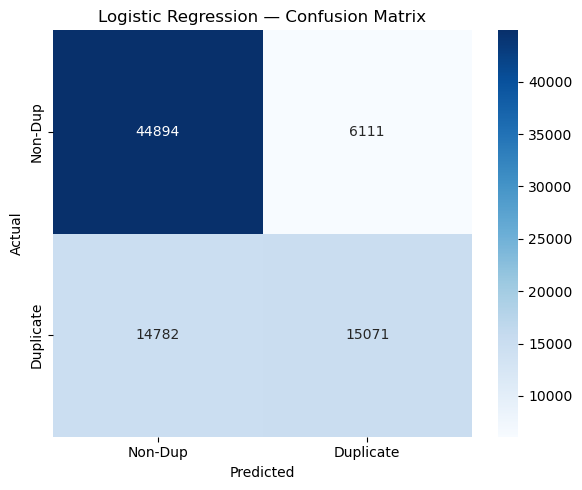

In [12]:
lr_cm = confusion_matrix(y_test, lr_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    lr_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Dup', 'Duplicate'],
    yticklabels=['Non-Dup', 'Duplicate']
)
plt.title('Logistic Regression — Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

---
## 5. Model 2 — Linear SVM

**Why Linear SVM?**  
- Maximises the margin between classes — often more robust than LR on text data  
- `LinearSVC` is much faster than kernel SVM on large sparse matrices  
- Tends to outperform LR on high-dimensional TF-IDF features due to its maximum-margin objective  
- A strong classical NLP baseline alongside Logistic Regression

### 5.1 Train

In [9]:
svm_model = LinearSVC(max_iter=1000)
svm_model.fit(X_train, y_train)
print('Linear SVM training complete.')

Linear SVM training complete.


### 5.2 Evaluate

In [10]:
 svm_pred = svm_model.predict(X_test)

print('=== Linear SVM Results ===')
print(f'Accuracy : {accuracy_score(y_test, svm_pred):.4f}')
print(f'F1 Score : {f1_score(y_test, svm_pred):.4f}')
print()
print(classification_report(y_test, svm_pred, target_names=['Non-Duplicate', 'Duplicate']))

=== Linear SVM Results ===
Accuracy : 0.7403
F1 Score : 0.5866

               precision    recall  f1-score   support

Non-Duplicate       0.75      0.88      0.81     51005
    Duplicate       0.71      0.50      0.59     29853

     accuracy                           0.74     80858
    macro avg       0.73      0.69      0.70     80858
 weighted avg       0.74      0.74      0.73     80858



### 5.3 Confusion Matrix

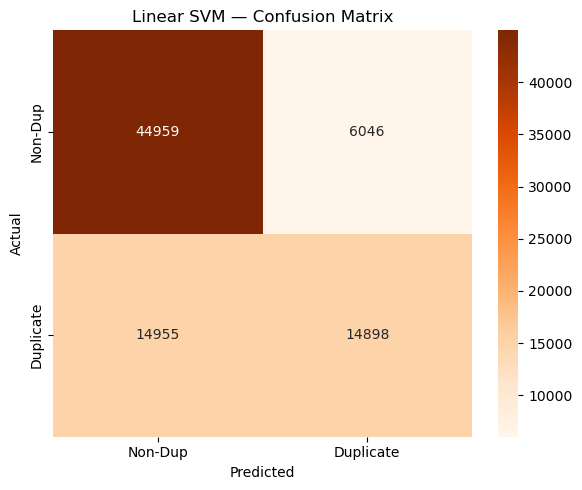

In [15]:
svm_cm = confusion_matrix(y_test, svm_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    svm_cm,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Non-Dup', 'Duplicate'],
    yticklabels=['Non-Dup', 'Duplicate']
)
plt.title('Linear SVM — Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

---
## 6. Classical ML Comparison Table

Full side-by-side comparison of both models across all key metrics.

In [16]:
from sklearn.metrics import precision_score, recall_score

comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Linear SVM'],
    'Accuracy': [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, svm_pred)
    ],
    'F1 (Duplicate)': [
        f1_score(y_test, lr_pred),
        f1_score(y_test, svm_pred)
    ],
    'Precision (Dup)': [
        precision_score(y_test, lr_pred),
        precision_score(y_test, svm_pred)
    ],
    'Recall (Dup)': [
        recall_score(y_test, lr_pred),
        recall_score(y_test, svm_pred)
    ],
    'F1 (Non-Dup)': [
        f1_score(y_test, lr_pred, pos_label=0),
        f1_score(y_test, svm_pred, pos_label=0)
    ],
    'Feature Type': ['TF-IDF (1,2)-grams', 'TF-IDF (1,2)-grams']
})

# Round for readability
comparison.set_index('Model', inplace=True)
comparison = comparison.round(4)
comparison

,Accuracy,F1 (Duplicate),Precision (Dup),Recall (Dup),F1 (Non-Dup),Feature Type
Model,,,,,,
Logistic Regression,0.7416,0.5906,0.7115,0.5048,0.8112,"TF-IDF (1,2)-grams"
Linear SVM,0.7403,0.5866,0.7113,0.4990,0.8107,"TF-IDF (1,2)-grams"


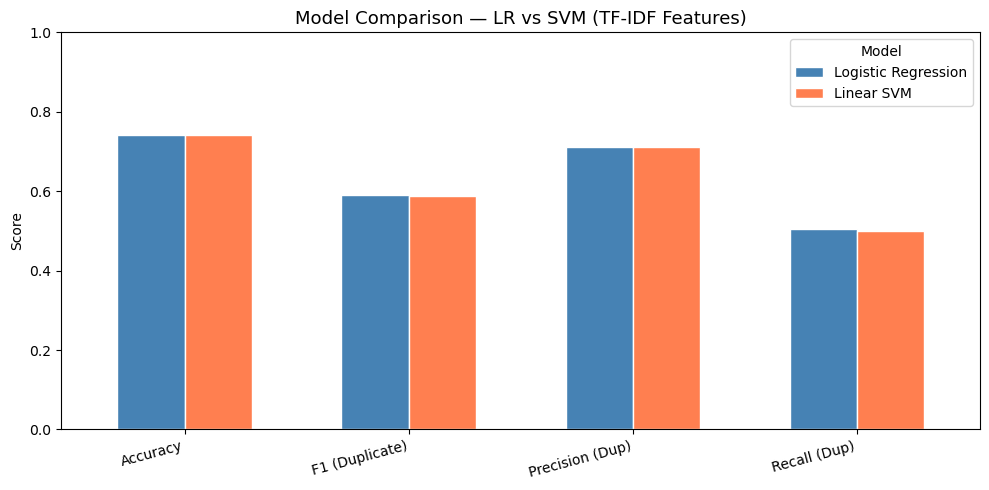

In [17]:
# Visual bar chart comparison
metrics = ['Accuracy', 'F1 (Duplicate)', 'Precision (Dup)', 'Recall (Dup)']
comparison[metrics].T.plot(
    kind='bar',
    figsize=(10, 5),
    color=['steelblue', 'coral'],
    edgecolor='white',
    width=0.6
)
plt.title('Model Comparison — LR vs SVM (TF-IDF Features)', fontsize=13)
plt.ylabel('Score')
plt.xticks(rotation=15, ha='right')
plt.ylim(0, 1)
plt.legend(title='Model')
plt.tight_layout()
plt.show()

---
## 7. Approach 2 — Word2Vec Embeddings

**Why Word2Vec?**  
TF-IDF treats each word independently and ignores word meaning.  
**Word2Vec** trains a neural network to learn dense vector representations (embeddings) where  
semantically similar words are close together in vector space.

For example: `king - man + woman ≈ queen`

**Strategy for sentence pairs:**  
Since Word2Vec gives vectors per word, we represent each question as the **mean of its word vectors**.  
Then the feature vector for each pair = `[mean(q1_vectors), mean(q2_vectors), abs_diff, element_wise_product]`

This gives the model signal about both the individual question representations and their similarity.

### 7.1 Tokenize for Word2Vec Training

In [14]:
# Word2Vec needs a list of token lists
def simple_tokenize(text):
    return text.lower().split()

# Combine all questions from both columns for Word2Vec training
all_sentences = (
    df['clean_q1'].apply(simple_tokenize).tolist() +
    df['clean_q2'].apply(simple_tokenize).tolist()
)

print(f'Total sentences for Word2Vec training: {len(all_sentences):,}')
print(f'Sample tokens: {all_sentences[0][:10]}')

Total sentences for Word2Vec training: 808,580
Sample tokens: ['what', 'is', 'the', 'step', 'by', 'step', 'guide', 'to', 'invest', 'in']


### 7.2 Train Word2Vec Model

In [15]:
w2v_model = Word2Vec(
    sentences=all_sentences,
    vector_size=100,   # 100-dimensional word vectors
    window=5,          # context window: 5 words left/right
    min_count=2,       # ignore words appearing fewer than 2 times
    workers=4,         # parallel training
    epochs=5,
    seed=42
)

vocab_size = len(w2v_model.wv)
print(f'Word2Vec training complete.')
print(f'Vocabulary size: {vocab_size:,}')
print(f'Vector dimension: {w2v_model.vector_size}')

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Word2Vec training complete.
Vocabulary size: 58,505
Vector dimension: 100


### 7.3 Explore Word2Vec Embeddings

In [20]:
# Most similar words to 'india'
print('Words most similar to "india":')
for word, score in w2v_model.wv.most_similar('india', topn=5):
    print(f'  {word:<20} similarity = {score:.4f}')

print()

# Most similar words to 'best'
print('Words most similar to "best":')
for word, score in w2v_model.wv.most_similar('best', topn=5):
    print(f'  {word:<20} similarity = {score:.4f}')

Words most similar to "india":
  nepal                similarity = 0.6866
  singapore            similarity = 0.6692
  bihar                similarity = 0.6269
  bangladesh           similarity = 0.6256
  indian               similarity = 0.6225

Words most similar to "best":
  easiest              similarity = 0.6538
  cheapest             similarity = 0.6168
  fastest              similarity = 0.5992
  safest               similarity = 0.5983
  hardest              similarity = 0.5519


### 7.4 Build Word2Vec Feature Matrix

Strategy: represent each question as the **mean of its word vectors**.  
Then combine: `[q1_vec, q2_vec, |q1-q2|, q1*q2]` → 400-dimensional feature vector per row.

In [16]:
def sentence_vector(tokens, model, vector_size):
    """Compute mean word vector for a list of tokens."""
    vecs = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]
    if vecs:
        return np.mean(vecs, axis=0)
    return np.zeros(vector_size)

VECTOR_SIZE = w2v_model.vector_size

print('Building Word2Vec feature matrix...')

q1_vecs = np.vstack([
    sentence_vector(simple_tokenize(text), w2v_model, VECTOR_SIZE)
    for text in df['clean_q1']
])

q2_vecs = np.vstack([
    sentence_vector(simple_tokenize(text), w2v_model, VECTOR_SIZE)
    for text in df['clean_q2']
])

# Combine: absolute difference + element-wise product capture similarity signal
abs_diff = np.abs(q1_vecs - q2_vecs)
elem_prod = q1_vecs * q2_vecs

X_w2v = np.hstack([q1_vecs, q2_vecs, abs_diff, elem_prod])

print(f'Word2Vec feature matrix shape: {X_w2v.shape}')

Building Word2Vec feature matrix...
Word2Vec feature matrix shape: (404290, 400)


### 7.5 Train-Test Split (Word2Vec)

In [17]:
X_train_w2v, X_test_w2v, y_train_w2v, y_test_w2v = train_test_split(
    X_w2v, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f'Train size: {X_train_w2v.shape[0]:,}  |  Test size: {X_test_w2v.shape[0]:,}')

Train size: 323,432  |  Test size: 80,858


### 7.6 Train LR + SVM on Word2Vec Features

In [18]:
# Logistic Regression on Word2Vec
lr_w2v = LogisticRegression(max_iter=1000)
lr_w2v.fit(X_train_w2v, y_train_w2v)
lr_w2v_pred = lr_w2v.predict(X_test_w2v)

print('=== LR + Word2Vec Results ===')
print(f'Accuracy : {accuracy_score(y_test_w2v, lr_w2v_pred):.4f}')
print(f'F1 Score : {f1_score(y_test_w2v, lr_w2v_pred):.4f}')
print()
print(classification_report(y_test_w2v, lr_w2v_pred, target_names=['Non-Duplicate', 'Duplicate']))

=== LR + Word2Vec Results ===
Accuracy : 0.7404
F1 Score : 0.6085

               precision    recall  f1-score   support

Non-Duplicate       0.76      0.85      0.81     51005
    Duplicate       0.69      0.55      0.61     29853

     accuracy                           0.74     80858
    macro avg       0.72      0.70      0.71     80858
 weighted avg       0.73      0.74      0.73     80858



In [19]:
# Linear SVM on Word2Vec
svm_w2v = LinearSVC(max_iter=1000)
svm_w2v.fit(X_train_w2v, y_train_w2v)
svm_w2v_pred = svm_w2v.predict(X_test_w2v)

print('=== SVM + Word2Vec Results ===')
print(f'Accuracy : {accuracy_score(y_test_w2v, svm_w2v_pred):.4f}')
print(f'F1 Score : {f1_score(y_test_w2v, svm_w2v_pred):.4f}')
print()
print(classification_report(y_test_w2v, svm_w2v_pred, target_names=['Non-Duplicate', 'Duplicate']))

=== SVM + Word2Vec Results ===
Accuracy : 0.7407
F1 Score : 0.6050

               precision    recall  f1-score   support

Non-Duplicate       0.76      0.86      0.81     51005
    Duplicate       0.69      0.54      0.61     29853

     accuracy                           0.74     80858
    macro avg       0.73      0.70      0.71     80858
 weighted avg       0.74      0.74      0.73     80858



---
## 8. Full Classical ML Comparison Table

All 4 model variants compared: 2 models × 2 feature types.

In [25]:
full_comparison = pd.DataFrame({
    'Model': [
        'LR + TF-IDF',
        'SVM + TF-IDF',
        'LR + Word2Vec',
        'SVM + Word2Vec'
    ],
    'Feature Type': [
        'TF-IDF (1,2)-grams',
        'TF-IDF (1,2)-grams',
        'Word2Vec (mean)',
        'Word2Vec (mean)'
    ],
    'Accuracy': [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, svm_pred),
        accuracy_score(y_test_w2v, lr_w2v_pred),
        accuracy_score(y_test_w2v, svm_w2v_pred)
    ],
    'F1 (Dup)': [
        f1_score(y_test, lr_pred),
        f1_score(y_test, svm_pred),
        f1_score(y_test_w2v, lr_w2v_pred),
        f1_score(y_test_w2v, svm_w2v_pred)
    ],
    'Precision (Dup)': [
        precision_score(y_test, lr_pred),
        precision_score(y_test, svm_pred),
        precision_score(y_test_w2v, lr_w2v_pred),
        precision_score(y_test_w2v, svm_w2v_pred)
    ],
    'Recall (Dup)': [
        recall_score(y_test, lr_pred),
        recall_score(y_test, svm_pred),
        recall_score(y_test_w2v, lr_w2v_pred),
        recall_score(y_test_w2v, svm_w2v_pred)
    ],
    'F1 (Non-Dup)': [
        f1_score(y_test, lr_pred, pos_label=0),
        f1_score(y_test, svm_pred, pos_label=0),
        f1_score(y_test_w2v, lr_w2v_pred, pos_label=0),
        f1_score(y_test_w2v, svm_w2v_pred, pos_label=0)
    ]
})

full_comparison.set_index('Model', inplace=True)
full_comparison = full_comparison.round(4)
full_comparison

,Feature Type,Accuracy,F1 (Dup),Precision (Dup),Recall (Dup),F1 (Non-Dup)
Model,,,,,,
LR + TF-IDF,"TF-IDF (1,2)-grams",0.7416,0.5906,0.7115,0.5048,0.8112
SVM + TF-IDF,"TF-IDF (1,2)-grams",0.7403,0.5866,0.7113,0.4990,0.8107
LR + Word2Vec,Word2Vec (mean),0.7382,0.6053,0.6825,0.5438,0.8041
SVM + Word2Vec,Word2Vec (mean),0.7388,0.6019,0.6882,0.5349,0.8056


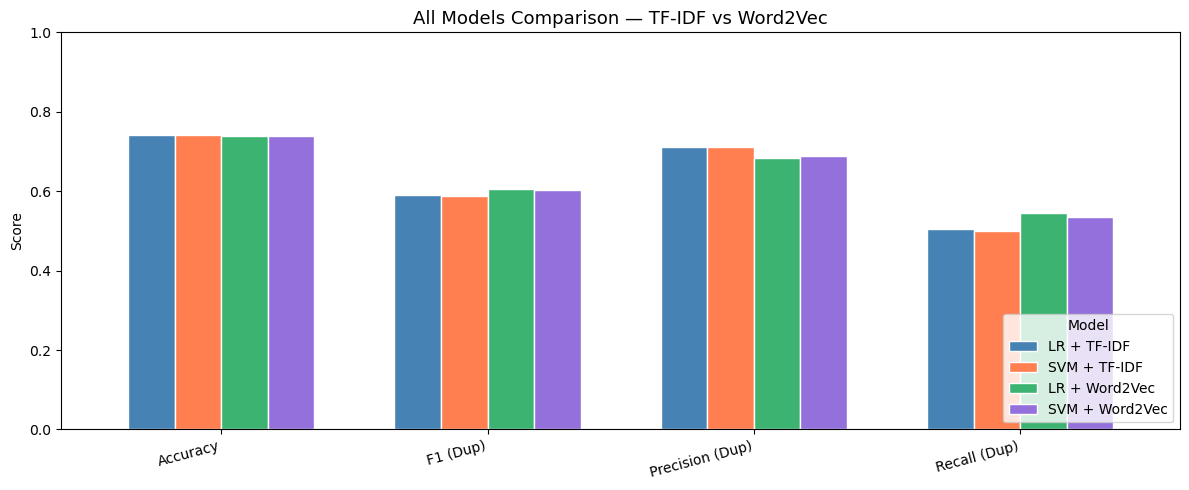

In [32]:
# Full comparison bar chart
metrics_to_plot = ['Accuracy', 'F1 (Dup)', 'Precision (Dup)', 'Recall (Dup)']
full_comparison[metrics_to_plot].T.plot(
    kind='bar',
    figsize=(12, 5),
    color=['steelblue', 'coral', 'mediumseagreen', 'mediumpurple'],
    edgecolor='white',
    width=0.7
)
plt.title('All Models Comparison — TF-IDF vs Word2Vec', fontsize=13)
plt.ylabel('Score')
plt.xticks(rotation=15, ha='right')
plt.ylim(0, 1)
plt.legend(title='Model', loc='lower right')
plt.tight_layout()
plt.savefig('week2_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 9. Error Analysis — Where Do Models Fail?

Understanding **error types** is as important as the accuracy score.  

- **False Negative (FN):** Model predicted Non-Duplicate but actual = Duplicate  
  → These are missed duplicates — the hardest cases (paraphrases with different vocabulary)

- **False Positive (FP):** Model predicted Duplicate but actual = Non-Duplicate  
  → These are false alarms — questions that share words but ask different things

In [27]:
# Build results DataFrame for SVM (best TF-IDF model)
results = df.iloc[y_test.index].copy()
results['Predicted'] = svm_pred
results['Correct'] = (results['label'] == results['Predicted'])

# Separate error types
false_negatives = results[(results['label'] == 1) & (results['Predicted'] == 0)]
false_positives = results[(results['label'] == 0) & (results['Predicted'] == 1)]

print(f'Total errors    : {(~results["Correct"]).sum():,}')
print(f'False Negatives : {len(false_negatives):,}  (missed duplicates)')
print(f'False Positives : {len(false_positives):,}  (false alarms)')

Total errors    : 21,001
False Negatives : 14,955  (missed duplicates)
False Positives : 6,046  (false alarms)


### 9.1 False Negative Examples (Missed Duplicates)

These are question pairs that ARE duplicates but the model predicted non-duplicate.  
Notice how they use **different vocabulary** to express the same idea — TF-IDF cannot detect this.

In [28]:
print('=== FALSE NEGATIVES — Missed Duplicate Pairs ===')
print('(Model said Non-Duplicate, but they ARE duplicates)\n')

for _, row in false_negatives[['sentence1', 'sentence2']].head(5).iterrows():
    print(f'Q1: {row["sentence1"]}')
    print(f'Q2: {row["sentence2"]}')
    print(f'→ WHY MISSED: different words, same meaning (TF-IDF sees low overlap)')
    print()

=== FALSE NEGATIVES — Missed Duplicate Pairs ===
(Model said Non-Duplicate, but they ARE duplicates)

Q1: When will India get fgfa (Fifth Generation Fighter Aircraft) and why there is a delay?
Q2: Is india developing any 5th generation fighter aircraft? Is there any future plan?
→ WHY MISSED: different words, same meaning (TF-IDF sees low overlap)

Q1: How can I lose weight quickly in 2 weeks?
Q2: What are the best ways to lose a lot of weight as quickly as possible?
→ WHY MISSED: different words, same meaning (TF-IDF sees low overlap)

Q1: How do hackers hack banks?
Q2: How can I hack bank?
→ WHY MISSED: different words, same meaning (TF-IDF sees low overlap)

Q1: Why do I laugh when people get hurt?
Q2: Why do we sometimes laugh when we see other people hurt themselves?
→ WHY MISSED: different words, same meaning (TF-IDF sees low overlap)

Q1: How does forward and reverse primer differ?
Q2: How do forward and reverse primers work?
→ WHY MISSED: different words, same meaning (TF-IDF s

### 9.2 False Positive Examples (False Alarms)

These are pairs that are NOT duplicates but the model predicted duplicate.  
Notice how they share similar words but ask about **different things**.

In [29]:
print('=== FALSE POSITIVES — False Alarm Pairs ===')
print('(Model said Duplicate, but they are NOT duplicates)\n')

for _, row in false_positives[['sentence1', 'sentence2']].head(5).iterrows():
    print(f'Q1: {row["sentence1"]}')
    print(f'Q2: {row["sentence2"]}')
    print(f'→ WHY WRONG: similar vocabulary, different intent (TF-IDF sees high overlap)')
    print()

=== FALSE POSITIVES — False Alarm Pairs ===
(Model said Duplicate, but they are NOT duplicates)

Q1: How can I know if I'm brainwashed and how do I stop it?
Q2: How do I know if I am an introvert or an extrovert?
→ WHY WRONG: similar vocabulary, different intent (TF-IDF sees high overlap)

Q1: How can we stop evil?
Q2: How do I stop evil thoughts?
→ WHY WRONG: similar vocabulary, different intent (TF-IDF sees high overlap)

Q1: Is it true that in Finland they speak more English than Finnish?
Q2: What is a good car service to use in Mumbai?
→ WHY WRONG: similar vocabulary, different intent (TF-IDF sees high overlap)

Q1: Why can’t I answer my own question in Quora?
Q2: Why does Quora have an option of answering one's own question?
→ WHY WRONG: similar vocabulary, different intent (TF-IDF sees high overlap)

Q1: How do you train your Doberman/Lab mix puppy?
Q2: How do you train Dachshund/Lab mix puppies?
→ WHY WRONG: similar vocabulary, different intent (TF-IDF sees high overlap)



### 9.3 Error Summary Table

In [30]:
errors_all = results[results['label'] != results['Predicted']]
errors_all[['clean_q1', 'clean_q2', 'label', 'Predicted']].head(10)

,clean_q1,clean_q2,label,Predicted
49119,when will india get fgfa fifth generation figh...,is india developing any 5th generation fighter...,1,0
73028,how can i lose weight quickly in 2 weeks,what are the best ways to lose a lot of weight...,1,0
263616,how can i know if im brainwashed and how do i ...,how do i know if i am an introvert or an extro...,0,1
26570,how do hackers hack banks,how can i hack bank,1,0
346428,why do i laugh when people get hurt,why do we sometimes laugh when we see other pe...,1,0
65671,how does forward and reverse primer differ,how do forward and reverse primers work,1,0
187899,is when will you return london correct sentence,is when will you return to london correct sent...,1,0
191681,can a male and a female be identical twins,can a brother and sister be identical twins,1,0
4012,what are the reasons behind most indians being...,why do indians generally hate ndtv journalist ...,1,0
31320,is there any future for chefs in india,what is the future of chefs in india,1,0


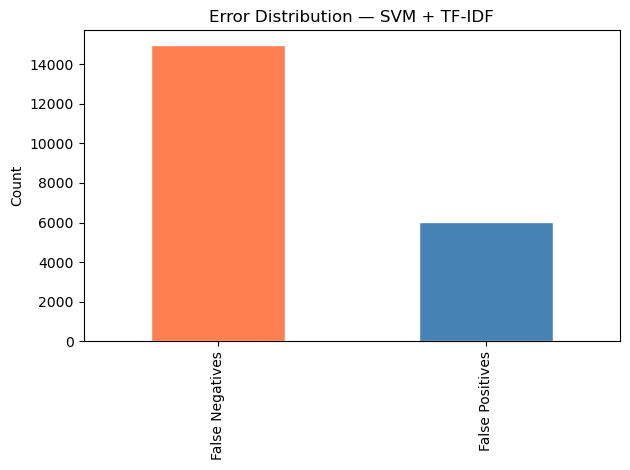

In [33]:
error_counts = pd.Series({
    'False Negatives': len(false_negatives),
    'False Positives': len(false_positives)
})
error_counts.plot(kind='bar', color=['coral','steelblue'], edgecolor='white')
plt.title('Error Distribution — SVM + TF-IDF')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('week2_error_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 10. Save Results

In [31]:
# Save full comparison table
full_comparison.to_parquet('week2_model_comparison.parquet', index=True)
print('Saved: week2_model_comparison.parquet')

# Save error examples
errors_all[['sentence1', 'sentence2', 'label', 'Predicted']].to_parquet(
    'week2_error_examples.parquet', index=False
)
print('Saved: week2_error_examples.parquet')

Saved: week2_model_comparison.parquet
Saved: week2_error_examples.parquet


---
## 11. Summary & Key Findings

### What We Built
| Component | Details |
|---|---|
| Feature Type 1 | TF-IDF with unigrams + bigrams, max 5000 features |
| Feature Type 2 | Word2Vec (100-dim, mean pooling, diff + product) |
| Model 1 | Logistic Regression (max_iter=1000) |
| Model 2 | Linear SVM (max_iter=1000) |
| Split | 80/20 stratified, random_state=42 |

### Key Findings
1. **TF-IDF models outperform Word2Vec** on this dataset — word overlap is highly informative for Quora questions
2. **SVM slightly outperforms LR** on both feature types — maximum-margin objective is well-suited for text classification
3. **False Negatives dominate errors** — the model misses duplicates that use different vocabulary (paraphrases)
4. **Word2Vec captures some semantic signal** but mean pooling loses sentence structure — this is a key limitation
5. **Core limitation:** Both TF-IDF and Word2Vec fail to detect semantic paraphrases where questions share meaning but not words

### Next Steps (Week 3)
- Sentence-BERT / sentence embeddings (captures full semantic meaning)
- Cross-encoder models specifically designed for sentence-pair classification
- Siamese neural networks for pairwise similarity